<a href="https://colab.research.google.com/github/sucharitacs24/bis-lab/blob/main/Grey%20Wolf%20Optmiser%20Algorithm-Recent%20Advances%20in%20Grey%20Wolf%20Optimizer%2C%20Its%20Versions%20and%20Applications%3A%20Review" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter number of wolves: 10
Enter number of iterations: 2

----- GWO RESULTS -----
Best Position: [-0.04506662  1.31838065]
Best Fitness: 1.740158536087759


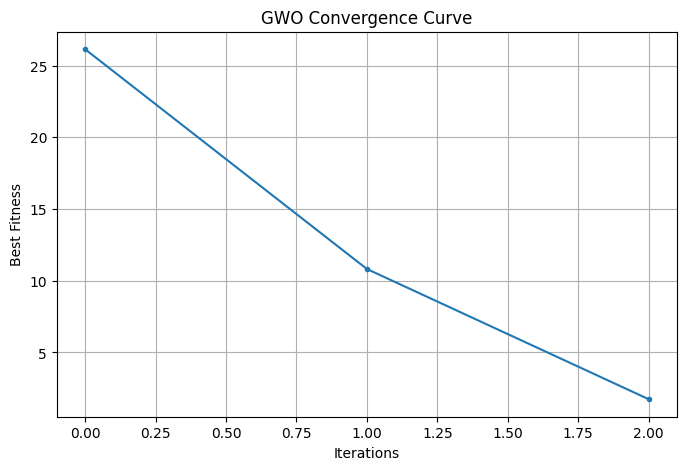

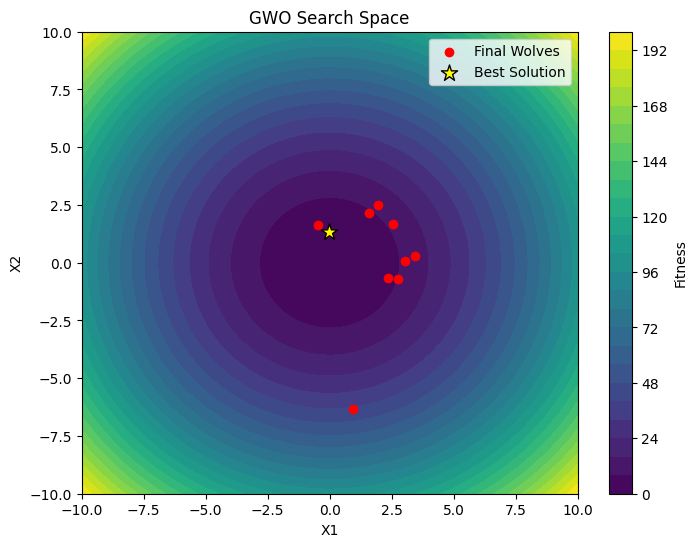

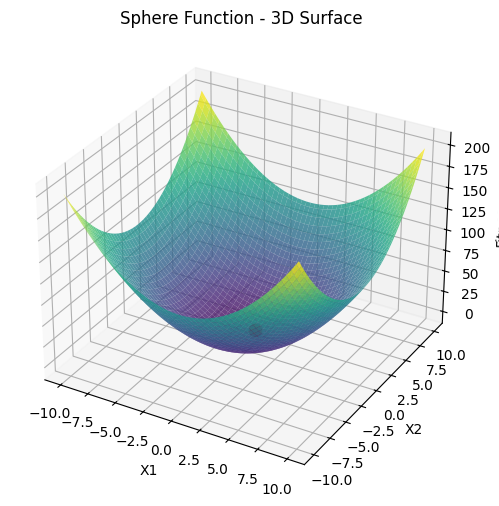

In [2]:

import numpy as np
import matplotlib.pyplot as plt

def fitness(position):
    return np.sum(position ** 2)


def GWO():


    n = int(input("Enter number of wolves: "))
    iterations = int(input("Enter number of iterations: "))

    dim = 2
    lb = -10
    ub = 10

    wolves = np.random.uniform(lb, ub, (n, dim))

    best_position = None
    best_fitness = float("inf")

    convergence = []


    for t in range(iterations):

        scores = np.array([fitness(w) for w in wolves])

        order = np.argsort(scores)

        alpha = wolves[order[0]].copy()
        beta = wolves[order[1]].copy()
        delta = wolves[order[2]].copy()

        if scores[order[0]] < best_fitness:
            best_fitness = scores[order[0]]
            best_position = alpha.copy()

        convergence.append(best_fitness)

        a = 2 - (2 * t / iterations)

        new_wolves = np.zeros_like(wolves)

        for i in range(n):

            for j in range(dim):

                r1, r2 = np.random.rand(), np.random.rand()
                A1 = 2 * a * r1 - a
                C1 = 2 * r2
                D_alpha = abs(C1 * alpha[j] - wolves[i, j])
                X1 = alpha[j] - A1 * D_alpha

                r1, r2 = np.random.rand(), np.random.rand()
                A2 = 2 * a * r1 - a
                C2 = 2 * r2
                D_beta = abs(C2 * beta[j] - wolves[i, j])
                X2 = beta[j] - A2 * D_beta


                r1, r2 = np.random.rand(), np.random.rand()
                A3 = 2 * a * r1 - a
                C3 = 2 * r2
                D_delta = abs(C3 * delta[j] - wolves[i, j])
                X3 = delta[j] - A3 * D_delta

                new_wolves[i, j] = (X1 + X2 + X3) / 3


        wolves = np.clip(new_wolves, lb, ub)

    scores = np.array([fitness(w) for w in wolves])
    idx = np.argmin(scores)

    if scores[idx] < best_fitness:
        best_fitness = scores[idx]
        best_position = wolves[idx].copy()

    convergence.append(best_fitness)

    print("\n----- GWO RESULTS -----")
    print("Best Position:", best_position)
    print("Best Fitness:", best_fitness)

    plt.figure(figsize=(8, 5))
    plt.plot(range(iterations + 1), convergence,
             marker='o', markersize=3)

    plt.title("GWO Convergence Curve")
    plt.xlabel("Iterations")
    plt.ylabel("Best Fitness")
    plt.grid(True)
    plt.show()

    x = np.linspace(lb, ub, 100)
    y = np.linspace(lb, ub, 100)

    X, Y = np.meshgrid(x, y)
    Z = X**2 + Y**2

    plt.figure(figsize=(8, 6))

    plt.contourf(X, Y, Z, levels=30, cmap='viridis')
    plt.colorbar(label="Fitness")

    plt.scatter(wolves[:, 0], wolves[:, 1],
                color='red', label='Final Wolves')

    plt.scatter(best_position[0], best_position[1],
                color='yellow', edgecolors='black',
                s=150, marker='*', label='Best Solution')

    plt.title("GWO Search Space")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.legend()
    plt.show()

    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection='3d')

    ax.plot_surface(X, Y, Z, cmap='viridis',
                    alpha=0.8)

    ax.scatter(best_position[0], best_position[1],
               best_fitness, color='red', s=80,
               label='Best Solution')

    ax.set_title("Sphere Function - 3D Surface")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_zlabel("Fitness")

    plt.show()


GWO()
